### Chatbot With Tool

In [1]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

groq_api_key=os.getenv("GROQ_API_KEY")

from langchain_groq import ChatGroq
llm=ChatGroq(groq_api_key=groq_api_key,model="openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.13', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x7716d6612a50>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x7716d66134d0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [4]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [6]:
tools=[tool,multiply]

In [7]:
llm_with_tools=llm.bind_tools(tools)
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.13', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x7716d6612a50>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x7716d66134d0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted

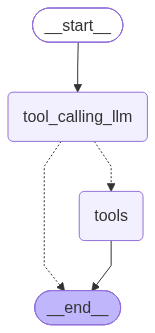

In [8]:
# StateGraph

from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode,tools_condition

# Node Definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}


# Graph
graph_builder=StateGraph(State)
graph_builder.add_node("tool_calling_llm",tool_calling_llm)
graph_builder.add_node("tools",ToolNode(tools))

# Add Edges
graph_builder.add_edge(START,"tool_calling_llm")
graph_builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)

graph_builder.add_edge("tools",END)

## compile the graph
graph=graph_builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
response=graph.invoke({"messages":"What is the recent ai news"})

In [13]:
response['messages'][-1].content

'{"query": "recent AI news 2026 November", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-october-2026", "title": "Google AI news: October 2026 updates", "content": "Breadcrumb\\n\\n1. Home\\n2. Innovation & AI\\n3. Technology\\n4. AI\\n\\n# The latest AI news we announced in October 2026\\n\\nNov 02, 2026\\n\\n|\\n\\n x.com\\n Facebook\\n LinkedIn\\n Mail\\n\\nHere’s a recap of some of our biggest AI updates from October, led by Gemini 4 Argon and Carbon, alongside our new world model Genie 4.\\n\\nBlog Team\\n\\nShare \\n\\n x.com\\n Facebook\\n LinkedIn\\n Mail\\n\\nListen to article \\n\\n minutes\\n\\nThis content is generated by Google AI. Generative AI is experimental [...] See how AI could improve patient-physician relationships in clinical care. In Google’s first publication in the main journal of The Lancet, researchers from Google and Beth Israel Deaconess Medical Center ev

In [14]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_b2f4297f-ff6f-4be4-af5f-b52f5e55ac30)
 Call ID: fc_b2f4297f-ff6f-4be4-af5f-b52f5e55ac30
  Args:
    query: recent AI news 2026 November
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 November", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-october-2026", "title": "Google AI news: October 2026 updates", "content": "Breadcrumb\n\n1. Home\n2. Innovation & AI\n3. Technology\n4. AI\n\n# The latest AI news we announced in October 2026\n\nNov 02, 2026\n\n|\n\n x.com\n Facebook\n LinkedIn\n Mail\n\nHere’s a recap of some of our biggest AI updates 

In [9]:
response=graph.invoke({"messages":"Multipply 5 and 6"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Multipply 5 and 6
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_b12e85ee-f44a-4ef2-b9e9-1433b776c5db)
 Call ID: fc_b12e85ee-f44a-4ef2-b9e9-1433b776c5db
  Args:
    a: 5
    b: 6
================================= Tool Message =================================
Name: multiply

30


In [16]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_a626b798-96d5-41a3-8fd7-ddc3c105cafe)
 Call ID: fc_a626b798-96d5-41a3-8fd7-ddc3c105cafe
  Args:
    query: recent AI news
    search_depth: basic
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://finance.yahoo.com/markets/stocks/articles/semiconductor-stock-looks-fairly-valued-171422762.html", "title": "ON Semiconductor (ON) Stock Looks Fairly Valued After AI Revenue News", "content": "That 38.9% one year return means anyone buying today is paying materially more than a year ago. The key issue is whether the underlying cash flow outlook justi

### ReAct Agent Architecture
- ACT
- OBSERVE
- REASON

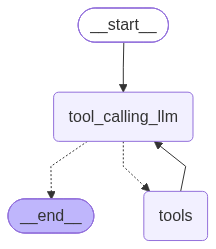

In [19]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [20]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_2ad5a7e0-d594-4b00-a48e-233381e8cce9)
 Call ID: fc_2ad5a7e0-d594-4b00-a48e-233381e8cce9
  Args:
    query: recent AI news 2026
    search_depth: basic
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-october-2026", "title": "Google AI news: October 2026 updates", "content": "For a tech expert, these October 2026 updates represent significant advancements in model capabilities, development tools, and hardware infrastructure. Key takeaways include the release of Gemini 4 Argon for complex coding a